# Chapter 10 - Panel Data

<h1>Table of Contents<span class="tocSkip"></span></h1>
<div class="toc"><ul class="toc-item"><li><span><a href="#10.2.2-Simulated-Panel-Data" data-toc-modified-id="10.2.2-Simulated-Panel-Data-1">10.2.2 Simulated Panel Data</a></span></li><li><span><a href="#10.2.3-OLS-Estimation-of-First-Differences" data-toc-modified-id="10.2.3-OLS-Estimation-of-First-Differences-2">10.2.3 OLS Estimation of First Differences</a></span></li><li><span><a href="#10.3.2-Difference-in-Difference-Estimator-in-Python" data-toc-modified-id="10.3.2-Difference-in-Difference-Estimator-in-Python-3">10.3.2 Difference in Difference Estimator in Python</a></span></li><li><span><a href="#10.4.1-Data-from-Card-and-Krueger-(1994)" data-toc-modified-id="10.4.1-Data-from-Card-and-Krueger-(1994)-4">10.4.1 Data from Card and Krueger (1994)</a></span></li><li><span><a href="#10.4.2-Difference-in-Difference-Estimates" data-toc-modified-id="10.4.2-Difference-in-Difference-Estimates-5">10.4.2 Difference in Difference Estimates</a></span></li><li><span><a href="#10.5.5-Fixed-Effects-Estimator-in-Python" data-toc-modified-id="10.5.5-Fixed-Effects-Estimator-in-Python-6">10.5.5 Fixed Effects Estimator in Python</a></span></li><li><span><a href="#10.6.1-NLSY97" data-toc-modified-id="10.6.1-NLSY97-7">10.6.1 NLSY97</a></span></li><li><span><a href="#10.6.2-Fixed-Effects-Estimators-of-the-Minimum-Wage" data-toc-modified-id="10.6.2-Fixed-Effects-Estimators-of-the-Minimum-Wage-8">10.6.2 Fixed Effects Estimators of the Minimum Wage</a></span></li><li><span><a href="#10.6.3-Are-Workers-Better-Off?" data-toc-modified-id="10.6.3-Are-Workers-Better-Off?-9">10.6.3 Are Workers Better Off?</a></span></li></ul></div>

## 10.2.2 Simulated Panel Data

In [1]:
# as in the previous chapters, we use numpy
import numpy as np

In [2]:
# remove Python warnings
import warnings
warnings.filterwarnings("ignore")

In [3]:
# setting the seed in Numpy
# the random numbers of Python are not the ones of R,
# so our results are close to the book but not the same
np.random.seed(123456789)

N = 1000  # 1000 individuals
T = 2     # 2 time periods
a = -2
b = 3
d = -4

# unobserved characteristic in the two periods.
# in R the vector c(5,6) goes down the rows of a matrix:
# 5 for the first period and 6 for the second period
# in numpy we write u as a column (2 rows, 1 column) to get the same thing
u = np.array([[5], [6]])

x1 = np.random.rand(N)
x2 = x1 + np.random.rand(N)  # change in X over time.

# creates a matrix T x N.
# one row for each time period and one column for each individual
x = np.array([x1, x2])

# additional unobserved characteristic
e = np.random.normal(size=(T, N))

# matrix with T rows and N columns.
y = a + b*x + d*u + e

## 10.2.3 OLS Estimation of First Differences

In [4]:
# using statsmodels and pandas, as in chapter 2
import statsmodels.formula.api as sm
import pandas as pd

# python starts counting at 0 and not at 1 like R:
# row 0 is the first period and row 1 is the second period
diffy = y[1, :] - y[0, :]
diffx = x[1, :] - x[0, :]

# pack the two differences in a dataframe
data = pd.DataFrame({'diffy': diffy, 'diffx': diffx})

lm1 = sm.ols(formula="diffy ~ diffx", data=data).fit()

In [5]:
# table of the coefficients, with the same columns as in the book
# the intercept is the time effect (true value d = -4)
# the coefficient of diffx is the estimate of b (true value 3)
tab_res = pd.DataFrame()
tab_res['Estimate'] = lm1.params
tab_res['Std. Error'] = lm1.bse
tab_res['t value'] = lm1.tvalues
tab_res['Pr(>|t|)'] = lm1.pvalues
tab_res

,Estimate,Std. Error,t value,Pr(>|t|)
Intercept,-3.949812,0.091132,-43.341739,1.221521e-231
diffx,2.854997,0.157237,18.157230,7.001115e-64


## 10.3.2 Difference in Difference Estimator in Python

In [6]:
def f_did(Y, treat):
    """
    Difference in difference table
    * Y is a matrix with 2 rows (the two periods)
      and one column for each individual
    * treat tells which individuals are treated
    """
    y1 = Y[0, :]  # first period
    y2 = Y[1, :]  # second period

    # creates the difference in difference matrix
    did = np.zeros((3, 3))

    # calculates the average outcomes for each
    did[0, 0] = np.mean(y2[treat==1])
    did[1, 0] = np.mean(y1[treat==1])
    did[0, 1] = np.mean(y2[treat==0])
    did[1, 1] = np.mean(y1[treat==0])

    # calculates the differences.
    did[2, 0] = did[0, 0] - did[1, 0]
    did[2, 1] = did[0, 1] - did[1, 1]
    did[0, 2] = did[0, 0] - did[0, 1]
    did[1, 2] = did[1, 0] - did[1, 1]
    did[2, 2] = did[2, 0] - did[2, 1]

    # name the rows and the columns of the matrix
    did = pd.DataFrame(did,
                       index=["Period 2", "Period 1", "Diff"],
                       columns=["Treated", "Not Treated", "Diff"])
    return did

In [7]:
np.random.seed(123456789)

# about half of the individuals are treated
# we set the same seed as above, so these draws are the ones of x1
# (it is the same in the book): the treated are the individuals
# with x1 below 0.5, and the two groups already differ in period 1
treat = np.random.rand(N) < 0.5

# this time the change is 1 for the treated group.
# in a sum, python counts True as 1 and False as 0
x2 = x1 + treat
x = np.array([x1, x2])
y = a + b*x + d*u + e

did1 = f_did(y, treat)

In [8]:
# the number at the bottom right is the estimate of b (true value 3)
did1

,Treated,Not Treated,Diff
Period 2,-22.237099,-23.765775,1.528676
Period 1,-21.224337,-19.733520,-1.490817
Diff,-1.012762,-4.032255,3.019493


## 10.4.1 Data from Card and Krueger (1994)

In [9]:
# the first column of the file has no name (these are the row names of R)
# we use it as the index of the dataframe
x = pd.read_csv('../data/cardkrueger.csv', index_col=0)
x.head()

,SHEET,CHAIN,CO_OWNED,STATE,SOUTHJ,CENTRALJ,NORTHJ,PA1,PA2,SHORE,...,FIRSTIN2,SPECIAL2,MEALS2,OPEN2R,HRSOPEN2,PSODA2,PFRY2,PENTREE2,NREGS2,NREGS112
1,46,1,0,0,0,0,0,1,0,0,...,0.08,1,2,6.50,16.50,1.03,.,0.94,4,4
2,49,2,0,0,0,0,0,1,0,0,...,0.05,0,2,10.00,13.00,1.01,0.89,2.35,4,4
3,506,2,1,0,0,0,0,1,0,0,...,0.25,.,1,11.00,11.00,0.95,0.74,2.33,4,3
4,56,4,1,0,0,0,0,1,0,0,...,0.15,0,2,10.00,12.00,0.92,0.79,0.87,2,2
5,61,4,1,0,0,0,0,1,0,0,...,0.15,0,2,10.00,12.00,1.01,0.84,0.95,2,2


In [10]:
# We define a bunch of functions to clean the data
# in an organised fashion

def get_period(df, ft, pt, time):
    """
    Employment of the restaurants in one period
    * SHEET is the firm ID.
    * FT - fulltime, PT - parttime.
    * ft and pt are the names of the two employment columns for this period
    * time is the number of the period, it goes in the column TIME
    """
    df_t = pd.DataFrame({'SHEET': df['SHEET'],
                         'FT': df[ft],
                         'PT': df[pt],
                         'STATE': df['STATE'],
                         'TIME': time})
    return df_t

def fix_labels(df):
    # there is an issue with the labeling in the data.
    # two firms with the same label.
    df.loc[df['SHEET']==407, 'SHEET'] = [4071, 4072]
    return df

def convert_col_to_numeric(df, col):
    # values which are not numbers (here ".") become NAs
    df[col] = pd.to_numeric(df[col], errors = 'coerce')
    return df

In [11]:
# and we perform the data cleaning using the .pipe operator
# on the original dataset x

# this includes the initial employment levels.
# column of 1s added to represent the initial time period.
x1 = (
    x
    .pipe(get_period, ft = 'EMPFT', pt = 'EMPPT', time = 1)
    .pipe(fix_labels)
)

# the second period of data.
x2 = (
    x
    .pipe(get_period, ft = 'EMPFT2', pt = 'EMPPT2', time = 2)
    .pipe(fix_labels)
)

# putting both periods together.
# FT and PT are read as text because of the "." in the file,
# we change them into numbers
x3 = (
    pd.concat([x1, x2], ignore_index=True)
    .pipe(convert_col_to_numeric, col = 'FT')
    .pipe(convert_col_to_numeric, col = 'PT')
)
x3.head()

,SHEET,FT,PT,STATE,TIME
0,46,30.0,15.0,0,1
1,49,6.5,6.5,0,1
2,506,3.0,7.0,0,1
3,56,20.0,20.0,0,1
4,61,6.0,26.0,0,1


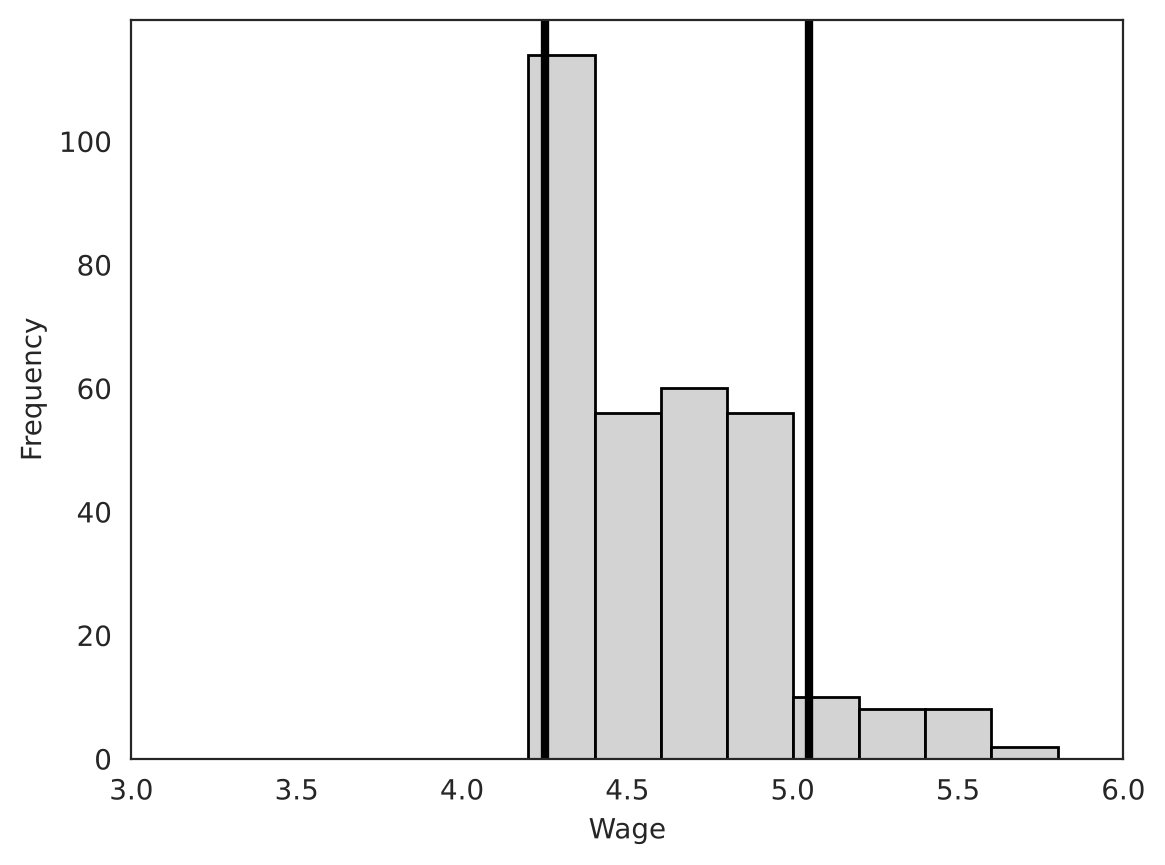

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# plotting with a R-looking style
sns.set_style('white')

# starting wage in the New Jersey restaurants (STATE is 1),
# before the minimum wage increase
# the "." become NAs and we remove them
wage_nj = pd.to_numeric(x.loc[x['STATE']==1, 'WAGE_ST'], errors='coerce')
wage_nj = wage_nj[wage_nj.isna()==False]

# bars of 20 cents, from 4.20 to 5.80
# R puts a wage of 5.00 in the bar (4.8, 5.0] and python in the bar [5.0, 5.2)
# we move the limits by a tenth of a cent to get the bars of the book
bins = np.arange(4.2, 5.81, 0.2) + 0.001

plt.hist(wage_nj, bins=bins, color='lightgrey', edgecolor='k')

# the two vertical lines are the minimum wage before (4.25) and after (5.05)
plt.axvline(4.25, color='k', linewidth=3)
plt.axvline(5.05, color='k', linewidth=3)

plt.xlim(3, 6)
plt.xlabel('Wage')
plt.ylabel('Frequency')
plt.show()

## 10.4.2 Difference in Difference Estimates

In [13]:
# total number of employees (full time + part time) in each period
period1 = x3[x3['TIME']==1]
period2 = x3[x3['TIME']==2]
emp1 = np.array(period1['FT'] + period1['PT'])
emp2 = np.array(period2['FT'] + period2['PT'])

# matrix with 2 rows (the two periods) and one column for each restaurant
Y = np.array([emp1, emp2])

# we keep the restaurants with no missing value
# the sum of a column is NA if one of the two periods is missing
index_na = np.isnan(Y.sum(axis=0))==False
Y1 = Y[:, index_na]

# the treated group is New Jersey (STATE is 1)
# the non-treated group is Pennsylvania (STATE is 0)
treat = np.array(period1['STATE']==1)
treat1 = treat[index_na]

did2 = f_did(Y1, treat1)

In [14]:
# same numbers as in the book
did2

,Treated,Not Treated,Diff
Period 2,26.604762,27.473684,-0.868922
Period 1,26.401587,29.710526,-3.308939
Diff,0.203175,-2.236842,2.440017


## 10.5.5 Fixed Effects Estimator in Python

In [15]:
def f_fe(Y, X=None, cross=True):
    """
    Fixed effects estimator
    * takes in the outcomes Y as a T x N matrix
      (rows are time periods, columns are individuals)
    * X is the treatment variable, a matrix of the same size, if available
    * cross=False to create fixed effects only in the time dimension
    """
    Y = np.array(Y)
    T = Y.shape[0]
    N = Y.shape[1]

    # we change the matrix into one long vector
    # python reads a matrix row by row (R reads it column by column):
    # first period for all the individuals, then second period, and so on
    y = Y.flatten()

    # number of the time period for each element of y: 1,1,...,1,2,2,...
    # np.arange(1, T+1) gives the numbers from 1 to T
    t = np.repeat(np.arange(1, T+1), N)
    data = pd.DataFrame({'y': y, 't': t})

    # set up for different cases
    if cross:  # create cross-section dummies
        # number of the individual for each element of y: 1,2,...,N,1,2,...
        data['c'] = np.tile(np.arange(1, N+1), T)
    if X is not None:  # create treatment variable
        data['treat'] = np.array(X).flatten()

    # lm() in R leaves out the rows with a missing value
    # we remove them before the regression to do the same
    data = data.dropna()

    # estimator
    # C() creates one dummy for each value of the variable,
    # like as.factor() in R
    if cross and X is not None:  # standard case
        lm1 = sm.ols(formula="y ~ treat + C(t) + C(c)", data=data).fit()
    else:
        if X is not None:  # no cross-section
            lm1 = sm.ols(formula="y ~ treat + C(t)", data=data).fit()
        else:  # no treatment
            lm1 = sm.ols(formula="y ~ C(t)", data=data).fit()
    return lm1

In [16]:
np.random.seed(123456789)

N = 100
T = 10
alpha = np.random.rand(N)  # one effect for each individual
gamma = np.random.rand(T)  # one effect for each time period
beta = 3
epsilon = np.random.normal(size=(T, N))
treat = np.random.rand(N) < 0.5

# matrix of outcomes with T rows and N columns
# numpy adds the vector alpha (length N) to each row of the matrix,
# so column i gets the alpha of individual i
# we write gamma as a column (T rows, 1 column),
# so row t gets the gamma of period t
y = alpha + gamma.reshape(T, 1) + epsilon

# in the code of the book the treatment occurs in the first row
# (row 0 in python), the other rows are the pre-treatment periods
y[0, :] = y[0, :] + beta*treat
treat1 = np.zeros((T, N))
treat1[0, :] = treat

We compare the different estimators on the simulated data:

In [17]:
# standard estimator
lm1 = f_fe(y, treat1)

# No individual fixed effects estimator
lm2 = f_fe(y, treat1, cross=False)

# Adjusted estimator
y0 = y[1:T, :]  # pre-treatment outcomes.
# calculate alpha.
# axis=0 gives the mean of each column (colMeans in R)
alphahat = np.mean(y0, axis=0)
# adjust outcome.
# numpy subtracts the vector alphahat from each row,
# so column i loses the mean of individual i
y2 = y - alphahat
lm3 = f_fe(y2, treat1, cross=False)

# Two step estimator
lm4 = f_fe(y0, cross=False)  # adjust for time effects.
# the residuals come as one long vector
# we put them back in a matrix with T-1 rows and N columns
y0_res = np.array(lm4.resid).reshape(T-1, N)
alpha_hat = np.mean(y0_res, axis=0)  # calculate alpha.
y3 = y - alpha_hat  # adjust outcome
lm5 = f_fe(y3, treat1, cross=False)

And we display the results in a summary table:

In [18]:
from statsmodels.iolib.summary2 import summary_col

# (1) standard, (2) no individual dummies, (3) adjusted, (4) two step
# we show the intercept and the treatment effect (true value 3)
# drop_omitted=True leaves out the coefficients of all the dummies
print(summary_col([lm1,lm2,lm3,lm5],
                  stars=True,
                  float_format='%0.3f',
                  model_names=['(1)','(2)','(3)','(4)'],
                  regressor_order=['Intercept','treat'],
                  drop_omitted=True,
                  info_dict={'N':lambda x: "{0:d}".format(int(x.nobs)),
                             'R2':lambda x: "{:.3f}".format(x.rsquared)}
            ))


                 (1)      (2)      (3)      (4)   
--------------------------------------------------
Intercept      0.919*** 1.013*** 0.002    1.035***
               (0.325)  (0.136)  (0.124)  (0.124) 
treat          3.002*** 3.051*** 3.002*** 3.002***
               (0.201)  (0.201)  (0.182)  (0.182) 
R-squared      0.444    0.316    0.356    0.356   
R-squared Adj. 0.376    0.309    0.350    0.350   
N              1000     1000     1000     1000    
R2             0.444    0.316    0.356    0.356   
Standard errors in parentheses.
* p<.1, ** p<.05, ***p<.01


## 10.6.1 NLSY97

In [19]:
x = pd.read_csv('../data/NLSY97Panel.csv')

# the file with the names of the variables has no header line
# header=None tells pandas that the first line is already a name
x_names = pd.read_csv('../data/NLSY97Panel_names.csv', header=None)

# the first (and only) column of x_names gives the names of the columns of x
x.columns = list(x_names[0])
x.head()

,PUBID_1997,YSCH_5000_1997,YINC_1700_1997,KEY!SEX_1997,KEY!BDATE_M_1997,KEY!BDATE_Y_1997,CV_CENSUS_REGION_1997,CV_MARSTAT_1997,CV_MSA_1997,CV_SAMPLE_TYPE_1997,...,CVC_HOURS_WK_YR_ALL_90_XRND,CVC_HOURS_WK_YR_ALL_91_XRND,CVC_HOURS_WK_YR_ALL_92_XRND,CVC_HOURS_WK_YR_ALL_93_XRND,CVC_HOURS_WK_YR_ALL_94_XRND,CVC_HOURS_WK_YR_ALL_95_XRND,CVC_HOURS_WK_YR_ALL_96_XRND,CVC_HOURS_WK_YR_ALL_97_XRND,CVC_HOURS_WK_YR_ALL_98_XRND,CVC_HOURS_WK_YR_ALL_99_XRND
0,1,10,-4,2,9,1981,1,-4,3,1,...,0,0,0,0,0,0,0,544,1100,682
1,2,8,-4,1,7,1982,1,-4,3,1,...,0,0,0,0,0,0,0,0,0,0
2,3,7,-4,2,9,1983,1,-4,3,1,...,0,0,0,0,0,0,0,0,0,0
3,4,9,-4,2,2,1981,1,-4,3,1,...,0,0,0,0,0,0,0,246,480,136
4,5,9,-4,1,10,1982,1,-4,3,1,...,0,0,0,0,0,0,0,0,0,600


In [20]:
# create two matrices, with 18 (years)
# rows 8984 (individuals) columns
# one for income and one for hours worked.
year = list(range(1997, 2015))  # the years from 1997 to 2014
year1 = ["97","98","99","00","01","02","03",
         "04","05","06","07","08",
         "09","10","11","12","13","14"]
# below we need both versions of year.

# the two matrices are full of NAs at the start
# W is for income and Y is for hours worked
W = np.full((18, 8984), np.nan)
Y = np.full((18, 8984), np.nan)

for i in range(0, 18):
    # + is used to concatenate strings (paste() in R).
    hrs_name = "CVC_HOURS_WK_YR_ALL_" + year1[i] + "_XRND"
    inc_name = "YINC_1700_" + str(year[i])
    # "in" asks whether something is an element of a set.
    # the negative values are codes for missing answers, they become NAs
    if hrs_name in x.columns:
        Y[i, :] = np.where(x[hrs_name] >= 0, x[hrs_name], np.nan)
    if inc_name in x.columns:
        W[i, :] = np.where(x[inc_name] >= 0, x[inc_name], np.nan)

In [21]:
# row 10 is the year 2007 (row 11 in R)
# calculates the wage rate for each person.
rate_07 = W[10, :]/Y[10, :]

# treated if earn less than 7.26/hour or no earnings in 2007.
low = (rate_07 < 7.26) | (W[10, :]==0) | (Y[10, :]==0)
x['treat'] = np.where(low, 1, 0)

# when income or hours are missing and none of the three conditions is true,
# R gives NA. numpy gives False when it compares a NA, so we put these NAs back
missing = np.isnan(W[10, :]) | np.isnan(Y[10, :])
x['treat'] = np.where(missing & (low==False), np.nan, x['treat'])

In [22]:
# number of treated (1), non-treated (0) and NAs
x['treat'].value_counts(dropna=False)

treat
0.0    3503
NaN    3316
1.0    2165
Name: count, dtype: int64

## 10.6.2 Fixed Effects Estimators of the Minimum Wage

In [23]:
N = 600  # reduce the size for computational reasons.
T = 18
y1 = Y[:, 0:N]

# treatment variable, for the first N individuals
# rows 10 to 17 are the years 2007 to 2014 (rows 11 to 18 in R)
treat1 = np.zeros((T, N))
for i in range(10, T):
    treat1[i, :] = x['treat'][0:N]

lm1 = f_fe(y1, treat1)

In [24]:
# adjusted estimator
N = 8984  # full data set
y0 = Y[0:10, 0:N]  # pre-treatment

# mean of the hours worked before the treatment, for each individual
# np.nanmean takes the mean without the NAs (na.rm = TRUE in R)
alpha_hat = np.nanmean(y0, axis=0)
y1 = Y - alpha_hat

treat1 = np.zeros((T, N))
for i in range(10, T):
    treat1[i, :] = x['treat'][0:N]

lm2 = f_fe(y1, treat1, cross=False)

For the two step estimator, the book subtracts the coefficients of the time dummies without adding the intercept for the years 1998 to 2006, and we do the same to get its numbers (with the intercept added, the estimate for treat goes from -274.28 to -274.45).

In [25]:
# two step estimator
lm3 = f_fe(y0, cross=False)

# the 10 coefficients (intercept and 9 time dummies) in a column,
# so that row t loses the coefficient of period t
coefs = np.array(lm3.params).reshape(10, 1)
y0_res = y0 - coefs
alpha_hat = np.nanmean(y0_res, axis=0)  # calculate alpha.
y3 = Y - alpha_hat  # adjust outcome
lm4 = f_fe(y3, treat1, cross=False)

In [26]:
# (1) standard estimator with 600 individuals
# (2) adjusted estimator, (3) two step estimator
print(summary_col([lm1,lm2,lm4],
                  stars=True,
                  float_format='%0.3f',
                  model_names=['(1)','(2)','(3)'],
                  regressor_order=['Intercept','treat'],
                  drop_omitted=True,
                  info_dict={'N':lambda x: "{0:d}".format(int(x.nobs)),
                             'R2':lambda x: "{:.3f}".format(x.rsquared)}
            ))


                   (1)         (2)         (3)    
--------------------------------------------------
Intercept      821.538***  -722.012*** 25.935***  
               (185.236)   (8.313)     (8.287)    
treat          -296.386*** -271.147*** -274.277***
               (40.853)    (7.821)     (7.797)    
R-squared      0.542       0.275       0.283      
R-squared Adj. 0.505       0.274       0.283      
N              8297        127107      127107     
R2             0.542       0.275       0.283      
Standard errors in parentheses.
* p<.1, ** p<.05, ***p<.01


## 10.6.3 Are Workers Better Off?

In [27]:
# the treated group
# the rows where treat is NA are left out, so we do not need na.rm here
treated = x[x['treat']==1]

a = np.mean(treated['YINC_1700_2007'])
b = np.mean(treated['CVC_HOURS_WK_YR_ALL_07_XRND'])
c = a/b  # 2007 wage rate
d = np.mean(treated['YINC_1700_2010'])  # 2010 income
e = np.mean(treated['CVC_HOURS_WK_YR_ALL_10_XRND'])  # 2010 hours

# actual less counter-factual
print(d - c*(e + 270))

4206.07030742321


The book takes these means on the columns of x, where the negative codes for missing answers are still there, so we also do it with the matrices W and Y, where they are NAs.

In [28]:
# row 10 is 2007 and row 13 is 2010
index_treat = np.array(x['treat']==1)

a = np.nanmean(W[10, index_treat])
b = np.nanmean(Y[10, index_treat])
c = a/b  # 2007 wage rate
d = np.nanmean(W[13, index_treat])  # 2010 income
e = np.nanmean(Y[13, index_treat])  # 2010 hours

# actual less counter-factual
print(d - c*(e + 270))

10727.509290722333
